# Лабораторная работа №1: регрессия

Предсказание качества красного и белого вина по данным [UCI Wine Quality](https://archive.ics.uci.edu/dataset/186/wine+quality). Сравниваем baseline, линейную регрессию, случайный лес и градиентный бустинг.

Полные дубликаты удаляем, чтобы каждая уникальная запись имела одинаковый вес. Происхождение повторов неизвестно. Параметры моделей выбираем по CV внутри train; test используем для итоговой оценки. Это переработка ранее исследованного набора данных.

## 1. Окружение

Фиксируем random_state=42 для воспроизводимости.

In [3]:
# Библиотеки, версии окружения и seed для воспроизводимости.
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

RANDOM_STATE = 42

print("Python:", sys.executable)
print("pandas:", pd.__version__)
print("scikit-learn:", sklearn.__version__)
from IPython.display import display, Markdown


Python: C:\Users\Tim\Documents\ChatGPT\Лабы по мл\.venv\Scripts\python.exe
pandas: 3.0.6
scikit-learn: 1.9.1


## 2. Загрузка и объединение данных

Источник: [UCI Wine Quality](https://archive.ics.uci.edu/dataset/186/wine+quality).
Cortez et al. (2009), DOI: 10.24432/C56S3T, лицензия CC BY 4.0.

Загружаем оригинальный архив один раз и сохраняем CSV в `data` рядом с Notebook.
При повторном запуске используем локальные файлы. В исходных CSV разделитель — `;`.
Каждая строка описывает образец вина; `quality` — целевая оценка качества.


In [4]:
# Загружаем CSV из UCI, если их нет локально, и читаем таблицы.
from pathlib import Path
from urllib.request import urlopen
from zipfile import ZipFile
from io import BytesIO

NOTEBOOK_DIR = Path.cwd()
if (NOTEBOOK_DIR / "regression" / "lab1.ipynb").exists():
    NOTEBOOK_DIR = NOTEBOOK_DIR / "regression"
DATA_DIR = NOTEBOOK_DIR / "data"
DATA_DIR.mkdir(exist_ok=True)

filenames = ["winequality-red.csv", "winequality-white.csv"]
if not all((DATA_DIR / name).exists() for name in filenames):
    url = "https://archive.ics.uci.edu/static/public/186/wine+quality.zip"

    with urlopen(url, timeout=60) as response:
        archive_bytes = response.read()

    with ZipFile(BytesIO(archive_bytes)) as archive:
        for name in filenames:
            (DATA_DIR / name).write_bytes(archive.read(name))

red = pd.read_csv(DATA_DIR / "winequality-red.csv", sep=";")
white = pd.read_csv(DATA_DIR / "winequality-white.csv", sep=";")
assert red.columns.equals(white.columns), "Схемы таблиц различаются"
print("Красное вино:", red.shape)
print("Белое вино:", white.shape)


Красное вино: (1599, 12)
Белое вино: (4898, 12)


### Объединение таблиц

Добавляем признак wine_type и складываем строки через pd.concat. Целевая переменная — quality.

In [5]:
# Объединяем вина, добавляем тип и сохраняем исходные данные.
wine = pd.concat(
    [red.assign(wine_type="red"), white.assign(wine_type="white")],
    ignore_index=True,
)

assert len(wine) == len(red) + len(white)
print("Общая таблица:", wine.shape)
display(wine.head())
display(wine["wine_type"].value_counts().rename("Количество образцов"))

raw_data = wine.copy()


Общая таблица: (6497, 13)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,wine_type
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,red
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,red
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,red
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red


wine_type
white    4898
red      1599
Name: Количество образцов, dtype: int64

### Первичная проверка

Проверяем типы, пропуски и повторы: по всей строке и отдельно по входным признакам без quality.

In [6]:
# Проверяем структуру, пропуски и повторы с учётом quality и без него.
wine.info()
print("\nПропуски по столбцам:")
display(wine.isna().sum().rename("Количество пропусков"))

feature_columns = wine.columns.drop("quality").tolist()

print("Полных повторов сверх первого:", wine.duplicated().sum())

print("Повторов по признакам сверх первого:",
      wine.duplicated(subset=feature_columns).sum())


<class 'pandas.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         6497 non-null   float64
 1   volatile acidity      6497 non-null   float64
 2   citric acid           6497 non-null   float64
 3   residual sugar        6497 non-null   float64
 4   chlorides             6497 non-null   float64
 5   free sulfur dioxide   6497 non-null   float64
 6   total sulfur dioxide  6497 non-null   float64
 7   density               6497 non-null   float64
 8   pH                    6497 non-null   float64
 9   sulphates             6497 non-null   float64
 10  alcohol               6497 non-null   float64
 11  quality               6497 non-null   int64  
 12  wine_type             6497 non-null   str    
dtypes: float64(11), int64(1), str(1)
memory usage: 660.0 KB

Пропуски по столбцам:


fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
wine_type               0
Name: Количество пропусков, dtype: int64

Полных повторов сверх первого: 1177
Повторов по признакам сверх первого: 1177


### Удаление дубликатов

В 6497 строках нет пропусков. Удаляем 1177 полных повторов, сохраняя первое вхождение. Совпадений признаков с разными quality не обнаружено. Большие значения автоматически не удаляем.

In [7]:
# Удаляем полные повторы, сохраняя номера исходных строк.
keep_mask = ~raw_data.duplicated(keep="first")
source_rows = pd.Series(raw_data.index[keep_mask].to_numpy(), name="source_row")

wine = raw_data.drop_duplicates(keep="first").reset_index(drop=True)
assert len(source_rows) == len(wine)
assert not wine.duplicated().any()
print("До очистки:", len(raw_data))
print("Удалено полных повторов:", len(raw_data) - len(wine))
print("После очистки:", wine.shape)
print("Повторов по входным признакам:", wine.duplicated(subset=feature_columns).sum())


До очистки: 6497
Удалено полных повторов: 1177
После очистки: (5320, 13)
Повторов по входным признакам: 0


In [8]:
# Выделяем 20% на test; одинаковые признаки остаются в одной группе.
from sklearn.model_selection import GroupShuffleSplit

groups = wine.groupby(
    feature_columns, sort=False, dropna=False
).ngroup()

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=RANDOM_STATE,
)

train_idx, test_idx = next(splitter.split(wine, groups=groups))

train = wine.iloc[train_idx].copy()
test = wine.iloc[test_idx].copy()

# Проверяем размеры выборок и отсутствие общих групп.
train_groups = set(groups.iloc[train_idx])
test_groups = set(groups.iloc[test_idx])
assert train_groups.isdisjoint(test_groups)

print("Train:", train.shape)
print("Test:", test.shape)
print(f"Доля строк в test: {len(test) / len(wine):.1%}")
print("Общих групп между train и test:", len(train_groups & test_groups))

assert len(train) + len(test) == len(wine)


Train: (4256, 13)
Test: (1064, 13)
Доля строк в test: 20.0%
Общих групп между train и test: 0


20% данных выделяем на test, остальные 80% — на обучение. Это компромисс между объёмом обучения и проверки. Одинаковые признаки объединяем в группы, не пересекающие выборки. Параметры и seed по test не подбираем: повторный выбор по его результатам завысил бы оценку качества.

,Количество,"Доля, %"
quality,,
3,26,0.61
4,168,3.95
5,1404,32.99
6,1865,43.82
7,666,15.65
8,123,2.89
9,4,0.09


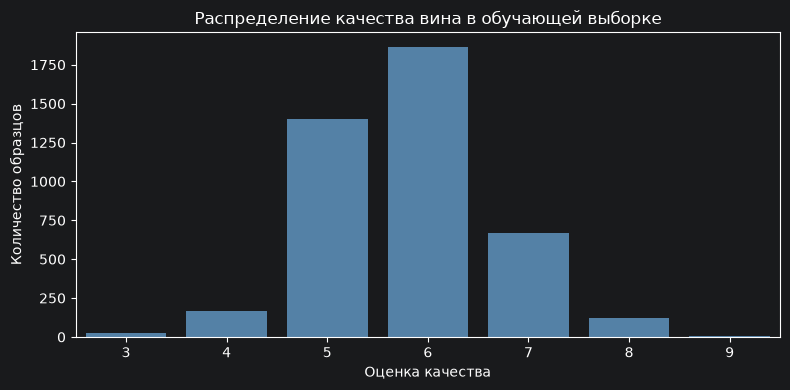

Оценки 5 и 6 составляют 76,8% train; крайние оценки редки, поэтому их сложнее предсказывать.

In [9]:
# Смотрим частоты оценок качества в train и делаем вывод о редких оценках.
quality_counts = train["quality"].value_counts().sort_index()

quality_summary = pd.DataFrame({
    "Количество": quality_counts,
    "Доля, %": (quality_counts / len(train) * 100).round(2),
})
display(quality_summary)

fig, ax = plt.subplots(figsize=(8, 4))

sns.countplot(
    data=train,
    x="quality",
    color="steelblue",
    ax=ax,
)

ax.set_title("Распределение качества вина в обучающей выборке")
ax.set_xlabel("Оценка качества")
ax.set_ylabel("Количество образцов")
plt.tight_layout()
plt.show()

display(Markdown('Оценки 5 и 6 составляют 76,8% train; крайние оценки редки, поэтому их сложнее предсказывать.'))


In [10]:
# Сравниваем масштабы, разброс и квантили числовых признаков.
numeric_features = train.select_dtypes(include="number").columns.drop("quality")

display(train[numeric_features].describe().T.round(3))


,count,mean,std,min,25%,50%,75%,max
fixed acidity,4256.0,7.202,1.321,3.800,6.400,6.900,7.700,15.900
volatile acidity,4256.0,0.343,0.167,0.080,0.230,0.300,0.410,1.580
citric acid,4256.0,0.318,0.148,0.000,0.240,0.310,0.400,1.660
residual sugar,4256.0,5.066,4.527,0.600,1.800,2.800,7.500,65.800
chlorides,4256.0,0.056,0.033,0.009,0.038,0.047,0.066,0.611
free sulfur dioxide,4256.0,30.234,18.081,1.000,16.000,28.000,41.000,289.000
total sulfur dioxide,4256.0,114.770,56.879,6.000,75.000,117.000,155.000,440.000
density,4256.0,0.995,0.003,0.987,0.992,0.995,0.997,1.039
pH,4256.0,3.225,0.162,2.720,3.110,3.210,3.330,4.010
sulphates,4256.0,0.530,0.144,0.220,0.430,0.510,0.600,1.980


Масштабы признаков различаются, поэтому для линейной модели используем стандартизацию. Максимумы сахара, хлоридов и свободного SO₂ заметно выше верхних квартилей; далее проверяем распределения.

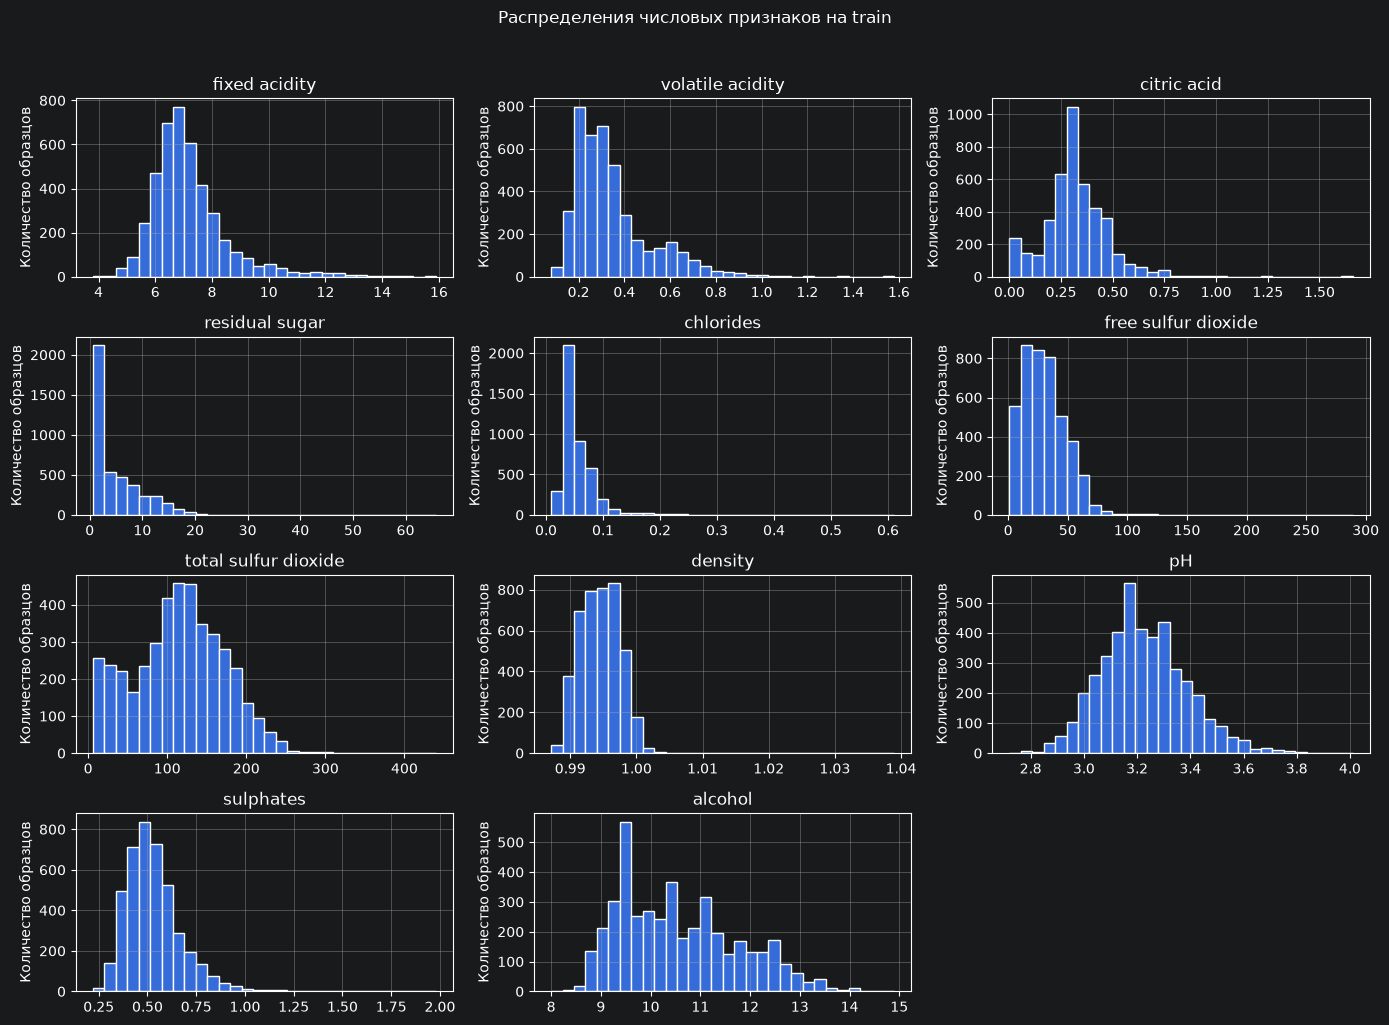

У сахара, хлоридов и свободного SO₂ длинные правые хвосты; pH распределён более симметрично. Необычные значения сами по себе не означают ошибку данных.

In [11]:
# Изучаем распределения признаков на train.
axes = train[numeric_features].hist(
    bins=30,
    figsize=(14, 10),
    layout=(4, 3),
    edgecolor="white",
)

for ax in axes.flat:
    if ax.get_visible():
        ax.set_ylabel("Количество образцов")

plt.suptitle("Распределения числовых признаков на train", y=1.02)
plt.tight_layout()
plt.show()

display(Markdown('У сахара, хлоридов и свободного SO₂ длинные правые хвосты; pH распределён более симметрично. Необычные значения сами по себе не означают ошибку данных.'))


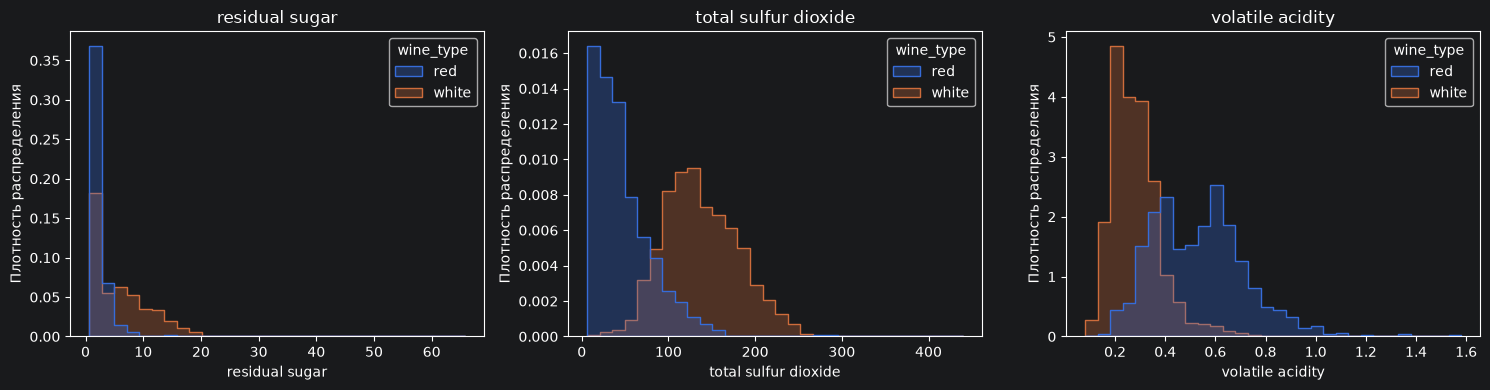

У белых вин обычно больше сахара и общего SO₂, у красных — выше летучая кислотность. Тип вина помогает учитывать эти различия.

In [12]:
# Сравниваем распределения красных и белых вин с нормировкой по плотности.
features_to_compare = [
    "residual sugar",
    "total sulfur dioxide",
    "volatile acidity",
]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for feature, ax in zip(features_to_compare, axes):

    sns.histplot(
        data=train,
        x=feature,
        hue="wine_type",
        bins=30,
        stat="density",
        common_norm=False,
        element="step",
        alpha=0.3,
        ax=ax,
    )
    ax.set_title(feature)
    ax.set_ylabel("Плотность распределения")

plt.tight_layout()
plt.show()

display(Markdown('У белых вин обычно больше сахара и общего SO₂, у красных — выше летучая кислотность. Тип вина помогает учитывать эти различия.'))


density                -0.324
volatile acidity       -0.263
chlorides              -0.212
fixed acidity          -0.077
residual sugar         -0.060
total sulfur dioxide   -0.049
pH                      0.025
free sulfur dioxide     0.054
sulphates               0.054
citric acid             0.107
alcohol                 0.469
Name: Корреляция с quality, dtype: float64

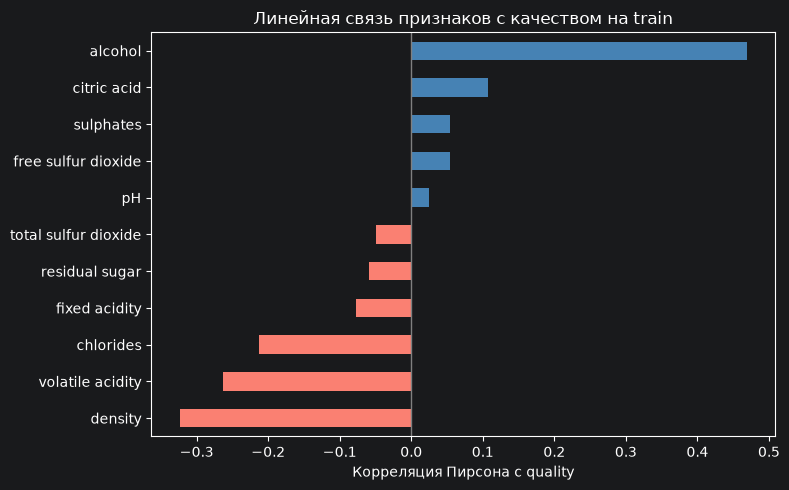

Alcohol положительно связан с quality; density, volatile acidity и chlorides — отрицательно. Корреляция не доказывает причинность.

In [13]:
# Оцениваем линейные связи признаков с quality на train.
correlations = (
    train[numeric_features]
    .corrwith(train["quality"])
    .sort_values()
)

display(correlations.rename("Корреляция с quality").round(3))

fig, ax = plt.subplots(figsize=(8, 5))

colors = [
    "steelblue" if value >= 0 else "salmon"
    for value in correlations
]

correlations.plot.barh(ax=ax, color=colors)
ax.axvline(0, color="gray", linewidth=1)
ax.set_xlabel("Корреляция Пирсона с quality")
ax.set_title("Линейная связь признаков с качеством на train")

plt.tight_layout()
plt.show()

display(Markdown('Alcohol положительно связан с quality; density, volatile acidity и chlorides — отрицательно. Корреляция не доказывает причинность.'))


In [14]:
# Сравниваем корреляции по типам вина и по всему train.
selected_features = [
    "alcohol",
    "density",
    "volatile acidity",
    "chlorides",
]

correlations_by_type = pd.DataFrame({
    wine_type: (
        part[selected_features]
        .corrwith(part["quality"])
    )
    for wine_type, part in train.groupby("wine_type")
})

correlations_by_type["all"] = correlations.reindex(selected_features)

display(correlations_by_type.round(3))


,red,white,all
alcohol,0.472,0.465,0.469
density,-0.159,-0.339,-0.324
volatile acidity,-0.393,-0.190,-0.263
chlorides,-0.131,-0.221,-0.212


Alcohol положительно связан с quality у обоих типов вина. Отрицательная связь volatile acidity сильнее у красных вин, density и chlorides — у белых. Это возможные различия зависимостей, полезность которых проверяем моделями.

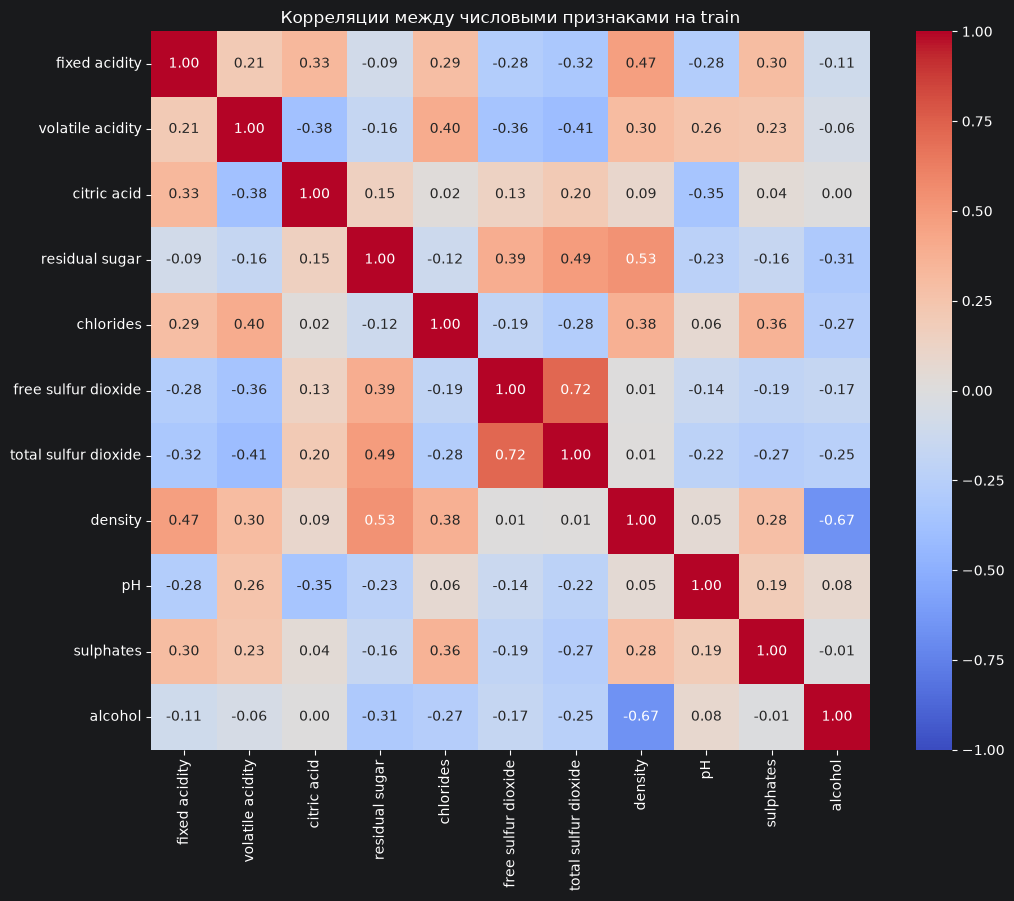

Связаны свободный и общий SO₂, а также density с alcohol и сахаром. Поэтому отдельные коэффициенты зависят и от остальных признаков.

In [15]:
# Проверяем, какие входные признаки связаны друг с другом.
corr_matrix = train[numeric_features].corr()

fig, ax = plt.subplots(figsize=(11, 9))

sns.heatmap(
    corr_matrix,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    annot=True,
    fmt=".2f",
    square=True,
    ax=ax,
)

ax.set_title("Корреляции между числовыми признаками на train")
plt.tight_layout()
plt.show()

display(Markdown('Связаны свободный и общий SO₂, а также density с alcohol и сахаром. Поэтому отдельные коэффициенты зависят и от остальных признаков.'))


## 3. Baseline, метрики и подготовка признаков

MAE = среднее абсолютное отклонение прогноза от истинной оценки; RMSE = квадратный корень из среднего квадрата отклонения. Обе метрики выражены в баллах quality, меньше — лучше. Квадрат ошибки сильнее выделяет большие промахи, поэтому RMSE обычно выше MAE; для одной выборки RMSE ≥ MAE.

Константа, минимизирующая MSE и RMSE, — среднее y_train: производная суммы (yᵢ − c)² по c равна нулю при c = mean(y). Для MAE оптимальна медиана, однако baseline выбираем по основной метрике RMSE.

Линейная регрессия: прогноз = свободный член + сумма произведений коэффициентов на признаки. Числовые признаки стандартизируем, чтобы сравнивать коэффициенты. Это не делает распределения нормальными и не устраняет корреляции. Тип вина кодируем одним бинарным признаком (white относительно red).

Пропусков в исходных данных нет. Imputer внутри Pipeline позволяет воспроизводимо обработать будущие пропуски; его статистики и scaler обучаются отдельно на обучающей части каждого CV-фолда. Для деревьев масштабирование не требуется.


In [16]:
# Подключаем инструменты для подготовки признаков и обучения.
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.model_selection import GroupKFold, GridSearchCV, cross_validate
from sklearn.metrics import root_mean_squared_error, mean_absolute_error
from IPython.display import display, Markdown

# Отделяем ответы от признаков и проверяем схему train/test.
X_train, y_train = train.drop(columns="quality"), train["quality"]
X_test, y_test = test.drop(columns="quality"), test["quality"]

groups_train = groups.iloc[train_idx].to_numpy()

numeric_columns = list(numeric_features)

assert "quality" not in X_train.columns
assert X_train.columns.equals(X_test.columns)

# Числа: медиана и при необходимости стандартизация; тип: red=0, white=1.
def preprocessing(scale):

    numeric_steps = [("imputer", SimpleImputer(strategy="median"))]

    if scale:
        numeric_steps.append(("scaler", StandardScaler()))

    return ColumnTransformer([

        ("numeric", Pipeline(numeric_steps), numeric_columns),

        ("type", OneHotEncoder(categories=[["red", "white"]],                            drop="first",
                               handle_unknown="ignore", sparse_output=False),
         ["wine_type"]),
    ], verbose_feature_names_out=False)

# Pipeline обучает обработку вместе с моделью внутри каждого CV-фолда.
def model_pipeline(model, scale=False):
    return Pipeline([("preprocessing", preprocessing(scale)), ("model", model)])

# Baseline предсказывает среднюю оценку обучающей выборки.
baseline = DummyRegressor(strategy="mean").fit(X_train, y_train)
print(f"Baseline всегда предсказывает {y_train.mean():.4f} балла")


Baseline всегда предсказывает 5.7899 балла


## 4. Модели и кросс-валидация

Используем общие 5 фолдов GroupKFold. Сравниваем среднюю CV RMSE, а стандартное отклонение показывает разброс ошибок. Для леса и бустинга проверяем по 4 конфигурации; выбранную модель заново обучаем на всём train.

Случайный лес усредняет прогнозы разных деревьев. Бустинг добавляет деревья последовательно, исправляя ошибки текущего прогноза. Разрыв между ошибками обучения и CV помогает заметить переобучение.

In [17]:
# Сравниваем модели на пяти общих CV-фолдах внутри train.
from joblib import parallel_config

with parallel_config(backend="threading"):

    cv = list(GroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
              .split(X_train, y_train, groups=groups_train))

    for fit_idx, valid_idx in cv:
        assert set(groups_train[fit_idx]).isdisjoint(groups_train[valid_idx])

    scoring = {"RMSE": "neg_root_mean_squared_error", "MAE": "neg_mean_absolute_error"}

    models = {"Baseline": baseline}
    cv_rows = []

    # Оцениваем baseline и линейную модель, затем обучаем их на всём train.
    for name, model in [
        ("Baseline", DummyRegressor(strategy="mean")),
        ("Linear Regression", model_pipeline(LinearRegression(), scale=True)),
    ]:

        scores = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring,
                                return_train_score=True, n_jobs=2)

        models[name] = clone(model).fit(X_train, y_train)

        cv_rows.append({"Модель": name, "CV RMSE": -scores["test_RMSE"].mean(),
                        "CV RMSE std": scores["test_RMSE"].std(),
                        "CV MAE": -scores["test_MAE"].mean(),
                        "Train RMSE (CV)": -scores["train_RMSE"].mean()})

    # Для леса и бустинга задаём сетки настроек.
    experiments = [
        ("Random Forest", RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE, n_jobs=1),
         {"model__max_features": [0.7, 1.0], "model__min_samples_leaf": [1, 2]}),
        ("Gradient Boosting", GradientBoostingRegressor(random_state=RANDOM_STATE),
         {"model__n_estimators": [200, 400], "model__learning_rate": [0.05],
          "model__max_depth": [2, 3], "model__min_samples_leaf": [5]}),
    ]

    # Выбираем настройки по средней CV RMSE; refit обучает победителя на всём train.
    for name, estimator, grid in experiments:
        print("Обучение:", name, flush=True)

        search = GridSearchCV(model_pipeline(estimator), grid, scoring=scoring, refit="RMSE", cv=cv, n_jobs=2, return_train_score=True)

        search.fit(X_train, y_train)

        models[name] = search.best_estimator_

        i = search.best_index_

        result = search.cv_results_

        cv_rows.append({"Модель": name,
                        "CV RMSE": -result["mean_test_RMSE"][i],
                        "CV RMSE std": result["std_test_RMSE"][i],
                        "CV MAE": -result["mean_test_MAE"][i],
                        "Train RMSE (CV)": -result["mean_train_RMSE"][i]})

        print("Выбраны параметры:", search.best_params_, flush=True)

    # Собираем метрики и выбираем лучшую модель по CV.
    cv_table = pd.DataFrame(cv_rows).set_index("Модель").sort_values("CV RMSE")
    display(cv_table.round(4))

    best_name = cv_table.drop(index="Baseline")["CV RMSE"].idxmin()

    best_model = models[best_name]


Обучение: Random Forest
Выбраны параметры: {'model__max_features': 0.7, 'model__min_samples_leaf': 1}
Обучение: Gradient Boosting
Выбраны параметры: {'model__learning_rate': 0.05, 'model__max_depth': 3, 'model__min_samples_leaf': 5, 'model__n_estimators': 400}


,CV RMSE,CV RMSE std,CV MAE,Train RMSE (CV)
Модель,,,,
Random Forest,0.6955,0.0143,0.5332,0.2587
Gradient Boosting,0.7031,0.0173,0.5460,0.5940
Linear Regression,0.7351,0.0264,0.5671,0.7324
Baseline,0.8828,0.0159,0.6968,0.8827


## 5. Коэффициенты и feature importance (важности признаков)

Коэффициент числового признака соответствует изменению прогноза при его росте на одно стандартное отклонение, при фиксированных остальных признаках. Для wine_type_white это переход red → white.

Важности деревьев — нормированные уменьшения критерия ошибки при обучении. Они могут распределяться между связанными признаками и зависеть от числа возможных разбиений. Коэффициенты и важности не доказывают причинность.

Для линейной регрессии рассматриваем коэффициенты, для Random Forest и Gradient Boosting — таблицу и общий график feature importance. Сравниваем оба ансамбля между собой, с линейной моделью и EDA.

,Коэффициент
alcohol,0.2918
wine_type_white,-0.2762
density,-0.2528
volatile acidity,-0.2255
residual sugar,0.2192
sulphates,0.1196
free sulfur dioxide,0.1061
total sulfur dioxide,-0.1004
pH,0.0807
fixed acidity,0.0790


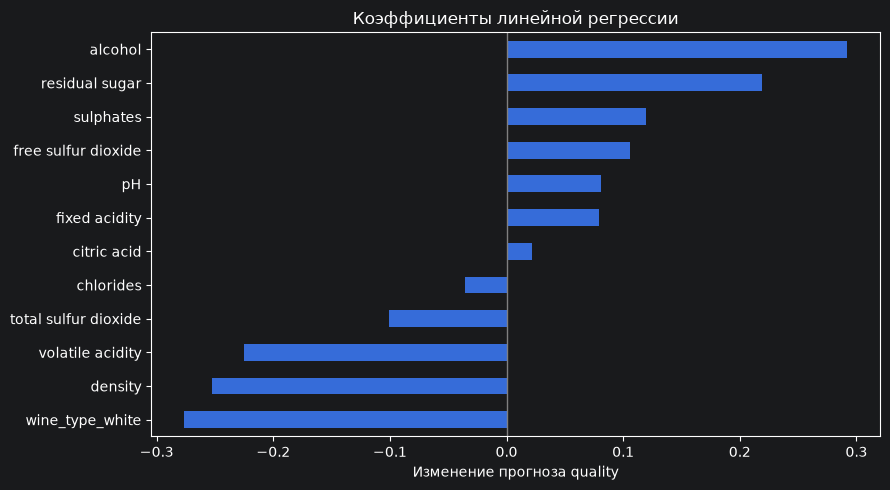

Среди числовых признаков крупнейшие по модулю коэффициенты у alcohol, density и volatile acidity. Рост alcohol связан с ростом прогноза, density и volatile acidity — со снижением при прочих равных.

,Random Forest,Gradient Boosting
alcohol,0.2363,0.4250
volatile acidity,0.1106,0.1438
free sulfur dioxide,0.0930,0.1091
density,0.0863,0.0277
sulphates,0.0794,0.0786
total sulfur dioxide,0.0743,0.0499
pH,0.0694,0.0368
chlorides,0.0642,0.0324
residual sugar,0.0641,0.0343
fixed acidity,0.0606,0.0290


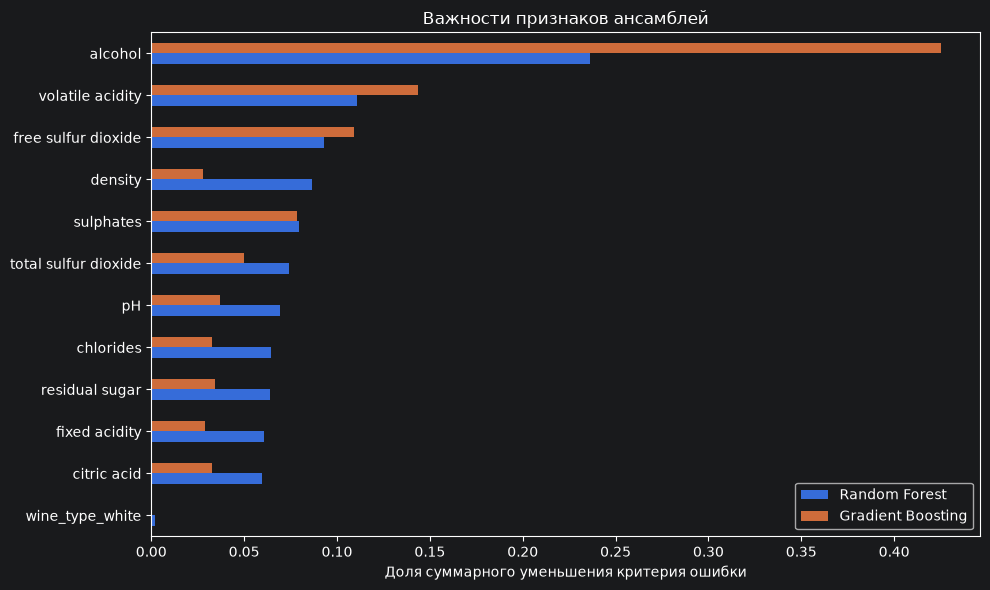

Оба ансамбля выделяют alcohol, volatile acidity и free sulfur dioxide; у бустинга важность alcohol выше. Alcohol и volatile acidity согласуются с EDA и линейной моделью. Free sulfur dioxide важен даже при слабой парной корреляции: деревья могут использовать нелинейные связи и сочетания признаков. Важность отражает вклад разбиений в обучение, а не процент снижения test RMSE; направление и причинность она не показывает.

In [18]:
# Рассматриваем коэффициенты линейной модели.
linear = models["Linear Regression"]
names = linear.named_steps["preprocessing"].get_feature_names_out()

coefficients = pd.Series(linear.named_steps["model"].coef_, index=names, name="Коэффициент")

display(coefficients.reindex(coefficients.abs().sort_values(ascending=False).index).to_frame().round(4))

fig, ax = plt.subplots(figsize=(9, 5))
coefficients.sort_values().plot.barh(ax=ax)
ax.axvline(0, color="gray", linewidth=1)
ax.set_title("Коэффициенты линейной регрессии")
ax.set_xlabel("Изменение прогноза quality")
plt.tight_layout(); plt.show()

display(Markdown('Среди числовых признаков крупнейшие по модулю коэффициенты у alcohol, density и volatile acidity. Рост alcohol связан с ростом прогноза, density и volatile acidity — со снижением при прочих равных.'))

# Сравниваем важности признаков леса и бустинга.
importance = pd.DataFrame({
    name: pd.Series(model.named_steps["model"].feature_importances_,
                    index=model.named_steps["preprocessing"].get_feature_names_out())
    for name, model in models.items() if name in ["Random Forest", "Gradient Boosting"]
})

display(importance.sort_values("Random Forest", ascending=False).round(4))
importance.sort_values("Random Forest").plot.barh(figsize=(10, 6))
plt.title("Важности признаков ансамблей")
plt.xlabel("Доля суммарного уменьшения критерия ошибки")
plt.tight_layout(); plt.show()

display(Markdown('Оба ансамбля выделяют alcohol, volatile acidity и free sulfur dioxide; у бустинга важность alcohol выше. Alcohol и volatile acidity согласуются с EDA и линейной моделью. Free sulfur dioxide важен даже при слабой парной корреляции: деревья могут использовать нелинейные связи и сочетания признаков. Важность отражает вклад разбиений в обучение, а не процент снижения test RMSE; направление и причинность она не показывает.'))

for name in importance:
    top = ", ".join(importance[name].nlargest(3).index)

top_linear = ", ".join(coefficients[numeric_columns].abs().nlargest(3).index)


## 6. Оценка на test

Вычисляем RMSE и MAE всех моделей на одной test-выборке. Победитель уже выбран по CV; по test его не меняем.

In [19]:
# Оцениваем все модели на одном test и сравниваем с baseline.
predictions = {name: model.predict(X_test) for name, model in models.items()}
test_rows = []

for name, pred in predictions.items():
    train_pred = models[name].predict(X_train)
    test_rows.append({"Модель": name,
                      "RMSE": root_mean_squared_error(y_test, pred),
                      "MAE": mean_absolute_error(y_test, pred),
                      "Train RMSE": root_mean_squared_error(y_train, train_pred)})

test_table = pd.DataFrame(test_rows).set_index("Модель")
test_table["Лучше baseline (RMSE)"] = test_table["RMSE"] < test_table.loc["Baseline", "RMSE"]
display(test_table.round(4))


,RMSE,MAE,Train RMSE,Лучше baseline (RMSE)
Модель,,,,
Baseline,0.8676,0.6942,0.8827,False
Linear Regression,0.7208,0.5602,0.7328,True
Random Forest,0.6629,0.5086,0.2572,True
Gradient Boosting,0.6835,0.5261,0.6075,True


## 7. Анализ ошибок лучшей модели

Здесь рассматриваем **Random Forest**, выбранный по минимальной средней CV RMSE (0,6955). Используем его прогнозы на отложенном test: RMSE = 0,6629, MAE = 0,5086. В коде выбор задаётся через `predictions[best_name]`.

Остаток = истинная оценка − прогноз: положительный — модель занизила оценку, отрицательный — завысила. Анализируем распределение ошибок, отдельные группы и крупнейшие промахи. Модель по этим результатам не перенастраиваем.

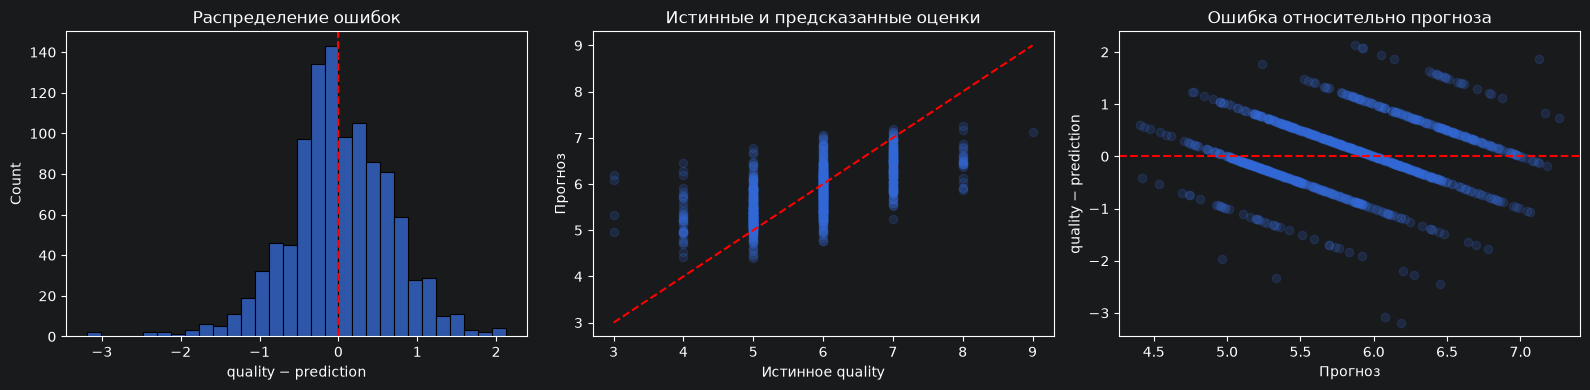

**Распределение ошибок.** Основная часть остатков сосредоточена около нуля, но встречаются крупные промахи. Отрицательный хвост доходит примерно до −3,2: отдельным винам модель сильно завышает качество.

**Истинные оценки и прогнозы.** Низкие оценки 3–4 часто завышаются, высокие 8–9 — занижаются. Прогнозы сжаты к средним значениям: одна общая метрика не показывает одинаково хорошую работу на всех уровнях quality.

**Ошибка относительно прогноза.** Видны диагональные полосы: quality принимает целые значения, а остаток равен quality − прогноз. Полосы сами по себе не означают ошибку кода; крупные отклонения показывают объекты для отдельного разбора.

,n,RMSE,MAE,Средняя ошибка,Средний прогноз
quality,,,,,
3,4.0,2.6896,2.6408,-2.6408,5.6408
4,38.0,1.3627,1.2813,-1.2813,5.2813
5,348.0,0.5597,0.4437,-0.4093,5.4093
6,458.0,0.4524,0.3676,0.1326,5.8674
7,190.0,0.7338,0.6296,0.6228,6.3772
8,25.0,1.5428,1.5053,1.5053,6.4947
9,1.0,1.8733,1.8733,1.8733,7.1267


**Таблица по quality.** n — число test-объектов; RMSE и MAE — величина ошибки; «Средняя ошибка» — средний остаток с учётом знака; «Средний прогноз» — средняя предсказанная оценка. Ошибки разных знаков могут взаимно компенсироваться в среднем остатке, поэтому он не заменяет MAE.

Для quality=3 средний прогноз 5,64: модель завышает оценку примерно на 2,64 балла. Для quality=8 прогноз 6,49 — занижение примерно на 1,51. В группе quality=6 — 458 объектов, а в группах 3 и 9 — только 4 и 1; сравнивать надёжность этих метрик нужно с учётом количества наблюдений.

,n,RMSE,MAE,Средняя ошибка,Средний прогноз
red,289.0,0.6081,0.4779,0.0181,5.6325
white,775.0,0.6822,0.5200,0.0151,5.8662


**Таблица по типу вина.** На этом test ошибка ниже для красных вин: RMSE 0,608 против 0,682 для белых. Средний остаток близок к нулю у обоих типов, но отдельные ошибки сохраняются. Это описание данного разбиения; число объектов различается (289 и 775), а статистическую значимость разницы мы не проверяли.

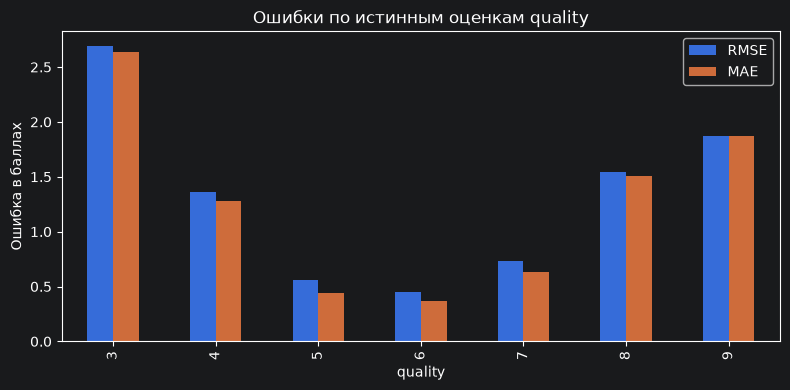

**График ошибок по quality.** Лучше всего среди групп предсказывается quality=6 (RMSE ≈ 0,452), хуже — quality=3 (≈ 2,690). Большой разрыв RMSE и MAE означает более неоднородные по величине ошибки внутри группы. У quality=9 всего один объект, поэтому RMSE и MAE совпадают и не характеризуют устойчивое качество на всех отличных винах.

Для крайних оценок мало обучающих примеров, а усреднение в листьях тянет прогнозы к середине диапазона. Поэтому редкие низкие оценки часто завышаются, высокие — занижаются; метрики малых test-групп менее устойчивы.

,source_row,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,wine_type,quality,prediction,residual,abs_error
4151,5008,6.2,0.23,0.35,0.7,0.051,24.0,111.0,0.9916,3.37,0.43,11.0,white,3,6.1867,-3.1867,3.1867
1729,2044,7.1,0.32,0.32,11.0,0.038,16.0,66.0,0.9937,3.24,0.40,11.5,white,3,6.0767,-3.0767,3.0767
4404,5335,6.5,0.32,0.48,8.0,0.026,18.0,88.0,0.9914,3.22,0.79,12.7,white,4,6.4533,-2.4533,2.4533
718,832,10.4,0.44,0.42,1.5,0.145,34.0,48.0,0.9983,3.38,0.86,9.9,red,3,5.3367,-2.3367,2.3367
2057,2430,7.4,0.17,0.40,5.5,0.037,34.0,161.0,0.9935,3.05,0.62,11.5,white,4,6.2733,-2.2733,2.2733


**Крупнейшие промахи.** Показаны пять test-объектов с максимальной абсолютной ошибкой. source_row — номер строки до очистки; quality и prediction — правильная оценка и прогноз; residual — ошибка со знаком, abs_error — её величина. Например, в исходной строке 5008 оценка 3, прогноз 6,19, ошибка около 3,19 балла.

Ниже для трёх объектов сравниваем характеристики с медианами train своего типа вина. Заметные отклонения помогают описать случаи, но не доказывают причину промаха: возможны нехватка похожих обучающих примеров и неучтённые факторы вкуса.

**Исходная строка 5008 (clean row 4151), white**: истинная оценка 3, прогноз 6.19, абсолютная ошибка 3.19. Заметные отклонения от медиан train по шкале общего IQR: pH=3.37 (медиана своего типа 3.18), residual sugar=0.7 (медиана своего типа 4.7). Это ориентиры для изучения, а не доказанные причины ошибки. Возможны недостаток похожих примеров и неучтённые факторы сенсорной оценки.

**Исходная строка 2044 (clean row 1729), white**: истинная оценка 3, прогноз 6.08, абсолютная ошибка 3.08. Заметные отклонения от медиан train по шкале общего IQR: residual sugar=11 (медиана своего типа 4.7), total sulfur dioxide=66 (медиана своего типа 133). Это ориентиры для изучения, а не доказанные причины ошибки. Возможны недостаток похожих примеров и неучтённые факторы сенсорной оценки.

**Исходная строка 5335 (clean row 4404), white**: истинная оценка 4, прогноз 6.45, абсолютная ошибка 2.45. Заметные отклонения от медиан train по шкале общего IQR: sulphates=0.79 (медиана своего типа 0.48), alcohol=12.7 (медиана своего типа 10.4). Это ориентиры для изучения, а не доказанные причины ошибки. Возможны недостаток похожих примеров и неучтённые факторы сенсорной оценки.

In [20]:
# Изучаем остатки и прогнозы лучшей по CV модели.
errors = X_test.copy()
errors.insert(0, "source_row", source_rows.iloc[test_idx].to_numpy())
errors["quality"] = y_test
errors["prediction"] = predictions[best_name]

errors["residual"] = errors["quality"] - errors["prediction"]
errors["abs_error"] = errors["residual"].abs()

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(errors["residual"], bins=30, ax=axes[0])
axes[0].axvline(0, color="red", linestyle="--")
axes[0].set(title="Распределение ошибок", xlabel="quality − prediction")
axes[1].scatter(y_test, predictions[best_name], alpha=0.18)
lo, hi = min(y_test.min(), predictions[best_name].min()), max(y_test.max(), predictions[best_name].max())
axes[1].plot([lo, hi], [lo, hi], "r--")
axes[1].set(title="Истинные и предсказанные оценки", xlabel="Истинное quality", ylabel="Прогноз")
axes[2].scatter(predictions[best_name], errors["residual"], alpha=0.18)
axes[2].axhline(0, color="red", linestyle="--")
axes[2].set(title="Ошибка относительно прогноза", xlabel="Прогноз", ylabel="quality − prediction")
plt.tight_layout(); plt.show()

display(Markdown('**Распределение ошибок.** Основная часть остатков сосредоточена около нуля, но встречаются крупные промахи. Отрицательный хвост доходит примерно до −3,2: отдельным винам модель сильно завышает качество.\n\n**Истинные оценки и прогнозы.** Низкие оценки 3–4 часто завышаются, высокие 8–9 — занижаются. Прогнозы сжаты к средним значениям: одна общая метрика не показывает одинаково хорошую работу на всех уровнях quality.\n\n**Ошибка относительно прогноза.** Видны диагональные полосы: quality принимает целые значения, а остаток равен quality − прогноз. Полосы сами по себе не означают ошибку кода; крупные отклонения показывают объекты для отдельного разбора.'))

# Сравниваем ошибки по оценкам качества и типам вина.
def error_summary(part):
    return pd.Series({"n": len(part), "RMSE": np.sqrt(np.mean(part["residual"] ** 2)),
                      "MAE": part["abs_error"].mean(), "Средняя ошибка": part["residual"].mean(),
                      "Средний прогноз": part["prediction"].mean()})

by_quality = pd.DataFrame({q: error_summary(part) for q, part in errors.groupby("quality")}).T
by_quality.index.name = "quality"
display(by_quality.round(4))

display(Markdown('**Таблица по quality.** n — число test-объектов; RMSE и MAE — величина ошибки; «Средняя ошибка» — средний остаток с учётом знака; «Средний прогноз» — средняя предсказанная оценка. Ошибки разных знаков могут взаимно компенсироваться в среднем остатке, поэтому он не заменяет MAE.\n\nДля quality=3 средний прогноз 5,64: модель завышает оценку примерно на 2,64 балла. Для quality=8 прогноз 6,49 — занижение примерно на 1,51. В группе quality=6 — 458 объектов, а в группах 3 и 9 — только 4 и 1; сравнивать надёжность этих метрик нужно с учётом количества наблюдений.'))
by_type = pd.DataFrame({t: error_summary(part) for t, part in errors.groupby("wine_type")}).T
display(by_type.round(4))

display(Markdown('**Таблица по типу вина.** На этом test ошибка ниже для красных вин: RMSE 0,608 против 0,682 для белых. Средний остаток близок к нулю у обоих типов, но отдельные ошибки сохраняются. Это описание данного разбиения; число объектов различается (289 и 775), а статистическую значимость разницы мы не проверяли.'))
fig, ax = plt.subplots(figsize=(8, 4))
by_quality[["RMSE", "MAE"]].plot.bar(ax=ax)
ax.set_title("Ошибки по истинным оценкам quality")
ax.set_ylabel("Ошибка в баллах")
plt.tight_layout(); plt.show()

display(Markdown('**График ошибок по quality.** Лучше всего среди групп предсказывается quality=6 (RMSE ≈ 0,452), хуже — quality=3 (≈ 2,690). Большой разрыв RMSE и MAE означает более неоднородные по величине ошибки внутри группы. У quality=9 всего один объект, поэтому RMSE и MAE совпадают и не характеризуют устойчивое качество на всех отличных винах.\n\nДля крайних оценок мало обучающих примеров, а усреднение в листьях тянет прогнозы к середине диапазона. Поэтому редкие низкие оценки часто завышаются, высокие — занижаются; метрики малых test-групп менее устойчивы.'))

# Разбираем крупнейшие промахи, сравнивая признаки с типичными значениями train.
worst = errors.nlargest(5, "abs_error")
display(worst.round(4))

display(Markdown('**Крупнейшие промахи.** Показаны пять test-объектов с максимальной абсолютной ошибкой. source_row — номер строки до очистки; quality и prediction — правильная оценка и прогноз; residual — ошибка со знаком, abs_error — её величина. Например, в исходной строке 5008 оценка 3, прогноз 6,19, ошибка около 3,19 балла.\n\nНиже для трёх объектов сравниваем характеристики с медианами train своего типа вина. Заметные отклонения помогают описать случаи, но не доказывают причину промаха: возможны нехватка похожих обучающих примеров и неучтённые факторы вкуса.'))

train_medians = train.groupby("wine_type")[numeric_columns].median()
train_iqr = train[numeric_columns].quantile(0.75) - train[numeric_columns].quantile(0.25)

for idx, row in worst.head(3).iterrows():
    deviations = ((row[numeric_columns].astype(float) - train_medians.loc[row["wine_type"]])
                  / train_iqr.replace(0, np.nan)).abs().nlargest(2)
    unusual = ", ".join(f"{f}={row[f]:.3g} (медиана своего типа {train_medians.loc[row['wine_type'], f]:.3g})"
                        for f in deviations.index)
    display(Markdown(f"**Исходная строка {int(row['source_row'])} (clean row {idx}), {row['wine_type']}**: истинная оценка {row['quality']}, "
                     f"прогноз {row['prediction']:.2f}, абсолютная ошибка {row['abs_error']:.2f}. "
                     f"Заметные отклонения от медиан train по шкале общего IQR: {unusual}. "
                     "Это ориентиры для изучения, а не доказанные причины ошибки. Возможны "
                     "недостаток похожих примеров и неучтённые факторы сенсорной оценки."))


## 8. Итоги

Из 6497 строк удалено 1177 полных повторов; осталось 5320: train — 4256, test — 1064 (20%). Пропусков и пересечений групп между выборками нет.

Все три модели превзошли baseline. По CV выбран Random Forest: test RMSE = **0,6629**, MAE = **0,5086**; RMSE ниже baseline на 23,6%. Ансамбли лучше линейной модели учитывают зависимости в этих данных; у леса заметен разрыв train/CV (0,2572 / 0,6955), поэтому переобучение остаётся существенным ограничением.

Наиболее важны alcohol, volatile acidity и free sulfur dioxide. Самые большие трудности — редкие крайние оценки: модель часто сдвигает их прогнозы к средним значениям.